# 9 Living crystals

## Active Brownian motion and mean square displacement

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
<strong>Note:</strong> This notebook contains the code for sections 9.1-9.2 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

In this chapter we study *active Brownian motion*.

**Scientific reading.** Howse et al., [*Self-Motile Colloidal Particles: From Directed Propulsion to Random Walk*](https://doi.org/10.1103/PhysRevLett.99.048102), *Physical Review Letters* **99**, 048102 (2007). See also the textbook's introductory discussion of Janus particles and its Figure 9.2.

All lengths below are in **µm**, times in **s**, translational diffusion in **µm²/s**, and rotational diffusion in **s⁻¹**. 

<a id="active-motion"></a>
## 9.1 Active Brownian motion

An active Brownian particle is described by its: 
- position $x$ and $y$, 
- orientation $\varphi$,
- and self-propulsion speed $v$ (or swimming speed). 

Its direction of motion changes because of rotational Brownian motion. See Eq. (9.1) in the textbook.

$\qquad \frac{dx}{dt}=v\cos\varphi\,+\sqrt{2D_T}\,W_x$

$\qquad \frac{dy}{dt}=v\sin\varphi\,+\sqrt{2D_T}\,W_y,$

$\qquad \frac{d\varphi}{dt}=\sqrt{2D_R}\,W_\varphi.$

The noise terms are independent.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, "../09_modules")

Let's simulate a single active Brownian particle (ABP)

Initial parameters:

In [2]:
dt = 0.01
D_T = 0.2
D_R = 0.5
speed = 3.0

# initial position 
r0 = np.array([0.0, 0.0])

# initial orientation 
phi0 = np.random.uniform(-np.pi, np.pi)

After 1 time step:

In [3]:
# direction (unit vector)
u = np.array([np.cos(phi0), np.sin(phi0)])

# change in position due to thermal noise
dr_noise = (
    np.sqrt(2 * D_T * dt) * np.random.normal(size=2)
)

# change in orientation due to thermal noise
dphi_noise = (
    np.sqrt(2 * D_R * dt) * np.random.normal()
)

# new position
r_new = (
    r0 
    + speed * u * dt 
    + dr_noise
)

# new orientation
phi_new = phi0 + dphi_noise

print(f"Initial Position: x = {r0[0]:.3e}, y = {r0[1]:.3e} µm")
print(f"Initial Orientation: {phi0:.3f} rad")

print(f"New Position: x = {r_new[0]:.3e}, y = {r_new[1]:.3e} µm")
print(f"New Orientation: {phi_new:.3f} rad")

Initial Position: x = 0.000e+00, y = 0.000e+00 µm
Initial Orientation: 0.513 rad
New Position: x = 3.442e-02, y = -2.074e-02 µm
New Orientation: 0.628 rad


Let's generate a trajetory over many time steps.

Note that the orientation `phi` won't be enforced to be between 0 and $2 \pi$ (or between $-\pi$ and $\pi$). 

In [4]:
steps = 500
r = np.zeros((steps + 1, 2))
phi = np.zeros(steps + 1)
phi[0] = np.random.uniform(-np.pi, np.pi)

Iterations:

In [5]:
for step in range(steps):
    u = np.array(
        [np.cos(phi[step]), np.sin(phi[step])]
    )
    r[step + 1] = (
        r[step]
        + speed * dt * np.array(u)
        + np.sqrt(2 * D_T * dt) * np.random.normal(size=2)
    )
    phi[step + 1] = (
        phi[step]
        + np.sqrt(2 * D_R * dt) * np.random.normal()
    )

Plot:

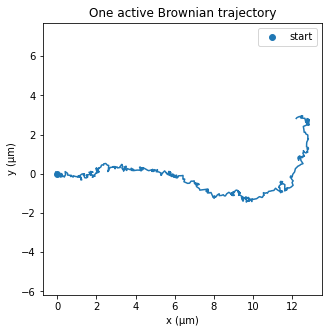

In [6]:
plt.figure(figsize=(5, 5))
plt.plot(r[:, 0], r[:, 1], lw=1.5)
plt.scatter(*r[0], label="start", s=35)
plt.axis("equal")
plt.xlabel("x (µm)")
plt.ylabel("y (µm)")
plt.title("One active Brownian trajectory")
plt.legend()
plt.show()

Persistence time: $\tau_r = D_R^{-1}$

Persistence length: $l = v \tau_r = v\ D_R^{-1}$

Let's see if we can make sense of these concepts in the results of the simulation above.

In [7]:
tau_r = 1 / D_R
print(f"Persistence time: tau_r = {tau_r:.3f} s")

l = speed * tau_r
print(f"Persistence length: l = {l:.3f} µm")

Persistence time: tau_r = 2.000 s
Persistence length: l = 6.000 µm


<a id="effect-speed"></a>
Let's see the effect of different swimming (or self-propulsion) speeds

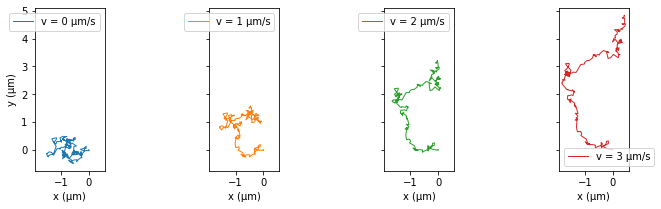

In [8]:
import active_brownian_motion as abm

seed = 17  # seed of the random number generator

dt = 0.01
D_T = 0.2
D_R = 0.5
steps = 200
speed_values = [0.0, 1.0, 2.0, 3.0]

fig, axes = plt.subplots(
    1, len(speed_values),
    figsize=(12, 3),
    sharex=True,
    sharey=True
)

for i, (ax, trial_speed) in enumerate(zip(axes, speed_values)):
    # use same noise 
    rng = np.random.default_rng(seed)
    path, _ = abm.simulate_abp(
        steps, 
        dt, 
        trial_speed, 
        D_T, 
        D_R,
        rng=rng  # same noise
    )
    ax.plot(path[:, 0], 
            path[:, 1], 
            lw=1,
            color=f"C{i}",
            label=f"v = {trial_speed:g} µm/s")
    ax.legend()
    ax.set_aspect("equal")
    ax.set_xlabel("x (µm)")
axes[0].set_ylabel("y (µm)")

plt.show()

<a id="msd"></a>
## 9.2 Mean square displacement

Following what was done for Chapter 5 (Brownian dynamics), we calculate the *mean square displacement* (MSD) for an active Brownian particle.

We can calculate the ***ensemble-averaged* MSD** (Eq. 9.2):

$$ \mathrm{e-MSD}(t) = \left\langle \lbrack x(t + \tau) - x(\tau) \rbrack^2 + \lbrack\ y(t + \tau) - y(\tau) \rbrack^2 \right\rangle$$

where:
- $t$ : lag time
- $\lbrack x(t), y(t)\rbrack$ : a realization of the active Brownian motion
- $\left\langle ... \right\rangle$ : ensemble average over independent realizations

We can calculate the ***time-averaged* MSD** (Eq. 9.3):

$$ \mathrm{t-MSD}(t) = \frac{1}{n} \sum_{i = 1}^{n} \left( \lbrack x(t + \tau_i) - x(\tau_i) \rbrack^2 + \lbrack\ y(t + \tau_i) - y(\tau_i) \rbrack^2 \right)$$

where:
- $t$ : lag time
- $\tau_i$ : time steps of the trajectory
- $\lbrack x(t), y(t)\rbrack$ : is a single realization of the active Brownian motion (possibly a *long enough* trajectory)
- $\frac{1}{n} \sum_{i = 1}^{n} \left( ... \right)$ : time average over all possible $\tau_i$ starting points for a lag time $t$


**Here, we consider a *time-averaged* MSD.**

Let's see how to implement a *time-averaged* MSD.

We start by generating a trajectory:

In [9]:
dt = 0.01
D_T = 0.2
D_R = 0.5
speed = 3.0

steps = 100000

r, phi = abm.simulate_abp(
    steps, 
    dt, 
    trial_speed, 
    D_T, 
    D_R,
)

We define the lag times to check and we implement:

In [10]:
n_lags = 1000

lag_steps = np.unique(
    np.geomspace(1, steps, n_lags).astype(int)
)
msd_t = np.empty(len(lag_steps))

for index, lag in enumerate(lag_steps):
    displacement = r[lag:] - r[:-lag]
    squared_displacement = (
        displacement[:, 0] ** 2 
        + displacement[:, 1] ** 2
    )
    msd_t[index] = np.mean(squared_displacement)
lag_times = lag_steps * dt

and plot with `loglog` :

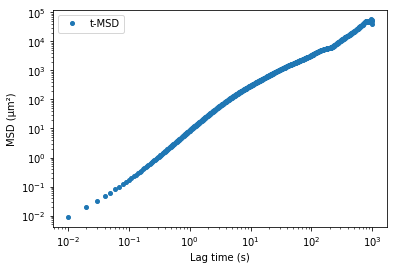

In [11]:
plt.loglog(lag_times, msd_t, "o", ms=4, label="t-MSD")
plt.xlabel("Lag time (s)")
plt.ylabel("MSD (µm²)")
plt.legend()
plt.show()

We compare with the ***analytical reference* for the MSD**:

With $t_r=1/D_R$, the theory predicts

$$\mathrm{MSD}(t)=4D_Tt+2v^2t_rt+2v^2t_r^2(e^{-t/t_r}-1).$$

At short lags: swimming produces a term $v^2t^2$; 

At long lags, the motion is diffusive with $D_{\mathrm{eff}}=D_T+v^2/(2D_R)$. 


Note: The short-lag *total* MSD can be dominated by the linear translational term, so a clean ballistic range is not automatic.

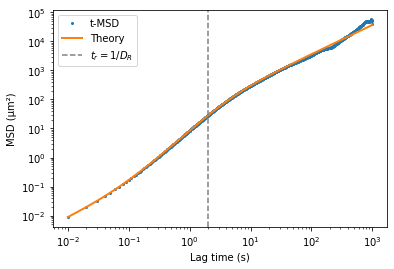

In [12]:
theory = abm.abp_msd_theory(lag_times, speed, D_T, D_R)

plt.loglog(lag_times, msd_t, "o", ms=2, label="t-MSD")
plt.loglog(lag_times, theory, "-", lw=2, label="Theory")
plt.axvline(1 / D_R, color="gray", ls="--", label="$t_r = 1/D_R$")
plt.xlabel("Lag time (s)")
plt.ylabel("MSD (µm²)")
plt.legend()
plt.show()

<a id="speed-msd"></a>
**Exercise 9.2** 

Effect of speed in the MSD.

We use the module.

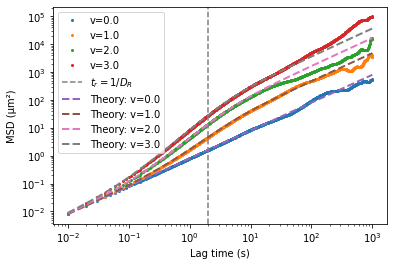

In [16]:
dt = 0.01
D_T = 0.2
D_R = 0.5
speed_values = [0.0, 1.0, 2.0, 3.0]

steps = 100000

# for calculating t-MSD
n_lags = 1000
lag_steps = np.unique(
    np.geomspace(1, steps, n_lags).astype(int)
)

for i, speed in enumerate(speed_values):
    r, _ = abm.simulate_abp(
        steps, 
        dt, 
        speed, 
        D_T, 
        D_R,
    )
    msd_t = abm.time_averaged_msd(r, lag_steps)
    plt.loglog(lag_times, msd_t, "o", ms=2, label=f"v={speed}")

plt.axvline(1 / D_R, color="gray", ls="--", label="$t_r = 1/D_R$")

for speed in speed_values:
    theory = abm.abp_msd_theory(lag_times, speed, D_T, D_R)
    plt.loglog(lag_times, theory, "--", lw=2, 
               label=f"Theory: v={speed}")

plt.xlabel("Lag time (s)")
plt.ylabel("MSD (µm²)")
plt.legend()
plt.show()


<a id="questions"></a>
## Questions

[Q1: Properties of Active Brownian motion](#q1)  
[Q2: Effect of speed on active Brownian trajectories](#q2)  
[Q3: Mean square displacement](#q3)  
[Q4: Effect of speed on MSD](#q4)  

<a id="q1"></a>
### Q1: Properties of active Brownian motion

Refer to [active Brownian motion](#active-motion) and the module [active_brownian_motion.py](../09_modules/active_brownian_motion.py)

[Go back to questions](#questions)

Consider the simulation of a single active Brownian particle in Section 9.1 and the function `abp_step()` in the module `active_brownian_motion.py`.

**a)** In the function `abp_step()`, identify the lines responsible for:
- Self-propulsion of the particle.
- Translational Brownian motion.
- Rotational Brownian motion.

**b)** Consider simulated trajectories of active particle in Section 9.1. Identify the noticeable features of active dynamics

**c)** The notebook calculates the persistence time and persistence length. Can you explain what they mean using the active particle trajectories obtained in Section 9.1?


<a id="q2"></a>
### Q2: Effect of speed on active Brownian trajectories

Refer to [active Brownian motion](#active-motion) and the [effect of speed](#effect-speed)

[Go back to questions](#questions)

Consider the simulations in Section 9.1, where active Brownian particles have translational diffusion coefficient $D_T=0.2\,\mu\mathrm{m}^2/\mathrm{s}$ and rotational diffusion coefficient $D_R=0.5\,\mathrm{s}^{-1}$.

**a)** Look at the trajectories for swimming speeds $v=0$ and $v=3\,\mu\mathrm{m/s}$. How do their trajectories differ?

**b)** Compare the trajectories for $v=1$ and $v=3\,\mu\mathrm{m/s}$. Does the faster particle always move farther from its starting point? Explain briefly why this may not be guaranteed for every simulation.

**c)** In the notebook, the same random seed is used when simulating particles with different swimming speeds. Why is this useful when comparing their trajectories?

<a id="q3"></a>
### Q3: Mean square displacement

Refer to [msd](#msd)

[Go back to questions](#questions)

**a)** The mean square displacement (MSD) of an active Brownian particle can scale as $t^2$ at intermediate times and as $t$ at long times. What causes this change in behavior? Explain.

**b)** Examine the function `time_averaged_msd()` in the module `active_brownian_motion.py`. How is the squared displacement calculated for a given lag time, and how are these values used to obtain the MSD?

**c)** Examine the function `abp_msd_theory()` in the module `active_brownian_motion.py`. How does the function handle the special case $D_R=0$, and how does the resulting expression for the MSD differ from the case $D_R>0$?


<a id="q4"></a>
### Q4: Effect of speed and rotational diffusion on MSD

Refer to [msd](#msd) and [effect of speed on MSD](#speed-msd)

[Go back to questions](#questions)

Consider the MSD calculations and plots in Section 9.2 and the function `abp_msd_theory()` in the module `active_brownian_motion.py`.

**a)** Examine the MSD curves for different swimming speeds. How does increasing the swimming speed affect the MSD?

**b)** Consider two active Brownian particles with the same swimming speed but different rotational diffusion coefficients. Which particle would you expect to have a larger MSD at long times: the one with higher or lower $D_R$? Explain briefly.

**c)** In the MSD plots, how does the difference between the curves for different swimming speeds change as the lag time increases?